# One site, end to end: a station record with NUTS, SVI and prediction through the gaps

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/ssm/ssm_one_site.ipynb)

This is the shortest complete pyrox-ssm workflow. We take one station with one daily series that has gaps, write one NumPyro model, fit it with two inference methods and draw a posterior predictive through the missing days. The later examples (many sites, a shared regional signal, non-Gaussian counts, ensembles, nonlinear dynamics) all start from this model and change one piece of it.

**pyrox-ssm capability shown:** `markov_gp_factor` with `mask=`, which adds the Kalman-filter marginal likelihood of a Markov GP as a NumPyro factor and leaves the missing observations out, and `MarkovGPPrior.condition(...).predict(...)`, which gives the smoothed posterior at arbitrary times. **Cost:** every log-density evaluation is one Kalman filter pass, $\mathcal{O}(N D_x^3)$ in the record length $N$ and the state dimension $D_x$. We measure the wall-clock times for NUTS, SVI and one gradient in section 7.

**What you'll learn:**

1. How to write a Markov-GP regression as a plain NumPyro function, with a mean function and a mask for missing days.
2. How to fit it with NUTS and with SVI, and how their hyperparameter posteriors compare with the truth.
3. How to predict the latent signal and new observations at dense times, through the gaps, averaged over the posterior.

For the Kalman recursions themselves see [Kalman filtering and RTS smoothing](markov_gp_kalman.ipynb). For maximum likelihood, mean-field versus full-rank guides and what a record can identify, see [Training a Markov GP](markov_gp_training.ipynb).

## Background

Our toy record is the daily mean air temperature $y_k$ (°C) at one station, where $t_k$ is the $k$-th day of the record, $k = 1, \ldots, N$. We model it as a seasonal climatology plus a weather anomaly plus sensor noise,

$$y_k = \mu(t_k) + f(t_k) + \varepsilon_k$$

$$\mu(t) = c + a \cos(\omega t) + b \sin(\omega t)$$

where $c, a, b \in \mathbb{R}$ (°C) set the climatology and $\omega = 2\pi / 365.25 \text{ days}^{-1}$. The anomaly is a Matérn-3/2 GP and the noise is independent and Gaussian,

$$f \sim \mathcal{GP}(0, k_\text{Matérn-3/2}(t, t'; \sigma_f^2, \ell))$$

$$\varepsilon_k \sim \mathcal{N}(0, \sigma_\varepsilon^2)$$

with the kernel variance $\sigma_f^2$, the lengthscale $\ell$ (days) and the noise variance $\sigma_\varepsilon^2$ all in $\mathbb{R}_{>0}$. The Matérn-3/2 kernel has an exact state-space form with a two-dimensional state $\mathbf{x}_k \in \mathbb{R}^{D_x}$, $D_x = 2$. So the Kalman filter gives us the marginal likelihood with $f$ integrated out. A day without an observation runs only the filter's predict step. So with $o_k \in \{0, 1\}$ the observation mask,

$$\log p(\mathbf{y} \mid \boldsymbol{\theta}) = \sum_{k=1}^{N} o_k \log \mathcal{N}(y_k; \mu(t_k) + \mathbf{H} \boldsymbol{\mu}_{x,k \mid k-1}, \mathbf{H} \boldsymbol{\Sigma}_{x,k \mid k-1} \mathbf{H}^\top + \sigma_\varepsilon^2)$$

where $\mathbf{y} \in \mathbb{R}^{N}$ is the record, $\boldsymbol{\mu}_{x,k \mid k-1} \in \mathbb{R}^{D_x}$ and $\boldsymbol{\Sigma}_{x,k \mid k-1} \in \mathbb{R}^{D_x \times D_x}$ are the one-step-ahead mean and covariance of the state, $\mathbf{H} \in \mathbb{R}^{1 \times D_x}$ is the measurement row, and $\boldsymbol{\theta} = (c, a, b, \sigma_f^2, \ell, \sigma_\varepsilon^2) \in \mathbb{R}^{6}$ are the six parameters that NUTS and SVI infer.

## Setup

We detect Colab and install `pyrox`, `pyrox-gp[colab]` (which pulls in `matplotlib` and `watermark`) and `pyrox-ssm` only when the notebook runs there.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
            "pyrox-ssm @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-ssm",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import time

import einx
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
from numpyro import handlers
from numpyro.infer import MCMC, NUTS, SVI, Trace_ELBO, init_to_median
from numpyro.infer.autoguide import AutoMultivariateNormal
from pyrox_ssm import (
    MarkovGPPrior,
    MaternSDE,
    markov_gp_factor,
    markov_gp_from_innovations,
)


jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark", "-v -m -p jax,equinox,numpyro,gaussx,pyrox,pyrox_ssm,matplotlib"
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
gaussx    : 0.6.15
pyrox     : 0.2.1
pyrox_ssm : 0.1.0
matplotlib: 3.10.9

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. A station record with gaps

We use two years of daily values, drawn from the model itself so that we know the true parameters: a 10 °C mean with an 8 °C annual cycle, a 2 °C weather anomaly that decorrelates over about four days, and 0.5 °C sensor noise. We simulate the anomaly path with `markov_gp_from_innovations`, which runs the SDE forward from standard normal innovations in linear time. Then we punch two kinds of gap into it: a 45-day logger outage in the second winter, and each day missing at random with probability 0.12. We store the missing days as `NaN`, as they would be in a real file, and the mask $o_k$ says which days are observed.

In [4]:
# Shapes: N = 730 days; D_x = 2 (the Matérn-3/2 state)

# ω = 2π / 365.25 days⁻¹, the annual angular frequency
OMEGA = 2.0 * jnp.pi / 365.25


def climatology(t, c, a, b):
    """Seasonal mean μ(t) = c + a cos(ωt) + b sin(ωt)."""
    return c + a * jnp.cos(OMEGA * t) + b * jnp.sin(OMEGA * t)


truth = {
    "mean_temp": 10.0,
    "cos_amp": -8.0,  # coldest near day 0 (1 January)
    "sin_amp": -1.5,
    "variance": 4.0,  # (2 °C)^2
    "lengthscale": 4.0,  # days
    "noise_var": 0.25,  # (0.5 °C)^2
}

N = 2 * 365
# t_k, days since 1 January of year 1
times = jnp.arange(N, dtype=jnp.float64)  # → (N,)

key_f, key_eps, key_gap = jr.split(jr.PRNGKey(2024), 3)
# today (pyrox_ssm)
# k_Matérn-3/2(t, t'; σ_f², ℓ) as a linear SDE
sde_true = MaternSDE(truth["variance"], truth["lengthscale"], order=1)
# today (pyrox_ssm)
prior_true = MarkovGPPrior(sde_true, times)
innovations = jr.normal(key_f, (N, prior_true.state_dim))  # → (N, D_x)
# today (pyrox_ssm)
# f(t_k), the SDE run forward from the innovations
f_true = markov_gp_from_innovations(prior_true, innovations)  # (N, D_x) → (N,)
# μ(t_k) = c + a cos(ω t_k) + b sin(ω t_k)
mu_true = climatology(  # (N,) → (N,)
    times, truth["mean_temp"], truth["cos_amp"], truth["sin_amp"]
)
noise_std = jnp.sqrt(truth["noise_var"])  # → ()
# ε_k ~ 𝒩(0, σ_ε²)
obs_noise = noise_std * jr.normal(key_eps, (N,))  # → (N,)
# y_k = μ(t_k) + f(t_k) + ε_k
y_full = mu_true + f_true + obs_noise  # (N,) → (N,)

# late January to early March, year 2
outage = (times >= 395) & (times < 440)  # → (N,) bool
dropout = jr.uniform(key_gap, (N,)) < 0.12  # → (N,) bool
# o_k = 1 on an observed day
mask = ~(outage | dropout)  # → (N,) bool
# what the station file holds
y = jnp.where(mask, y_full, jnp.nan)  # → (N,)

print(f"N = {N} days, observed = {int(mask.sum())}, missing = {int((~mask).sum())}")
print(
    f"  outage: {int(outage.sum())} days, "
    f"random dropouts: {int((dropout & ~outage).sum())} days"
)

N = 730 days, observed = 596, missing = 134
  outage: 45 days, random dropouts: 89 days


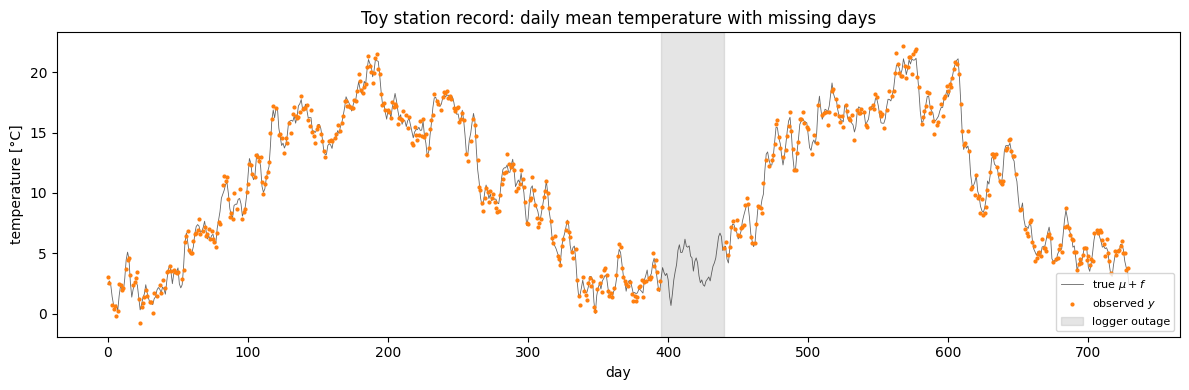

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(times, mu_true + f_true, "k-", lw=0.6, alpha=0.6, label=r"true $\mu + f$")
ax.scatter(times[mask], y[mask], c="C1", s=4, label="observed $y$", zorder=5)
ax.axvspan(395, 440, color="grey", alpha=0.2, label="logger outage")
ax.set_xlabel("day")
ax.set_ylabel("temperature [°C]")
ax.set_title("Toy station record: daily mean temperature with missing days")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 2. The model as a plain NumPyro function

Every parameter is an ordinary `numpyro.sample` site. We choose priors that say what a climatologist would say before seeing this station: a mean somewhere within $\pm 20$ °C of 10 °C, a seasonal amplitude of up to about 10 °C, an anomaly of a couple of degrees that lasts about a week, and sensor noise well below a degree. We pass the mean function to `MarkovGPPrior` as `mean_fn`. Then `markov_gp_factor` adds the masked Kalman log marginal as a factor site named `"y"`. The `NaN`s in `y` are safe, because masked entries are zeroed before any arithmetic, so they reach neither the value nor the gradient.

In [6]:
def station_model(times, y, mask):
    # Shapes: N = 730 days; D_θ = 6 parameters

    # today (numpyro): the six sample sites of θ
    # c ~ 𝒩(10, 10²)
    c = numpyro.sample("mean_temp", dist.Normal(10.0, 10.0))
    # a ~ 𝒩(0, 10²)
    a = numpyro.sample("cos_amp", dist.Normal(0.0, 10.0))
    # b ~ 𝒩(0, 10²)
    b = numpyro.sample("sin_amp", dist.Normal(0.0, 10.0))
    # σ_f² ~ LogNormal(log 2, 1)
    variance = numpyro.sample("variance", dist.LogNormal(jnp.log(2.0), 1.0))
    # ℓ ~ LogNormal(log 7, 1)
    lengthscale = numpyro.sample("lengthscale", dist.LogNormal(jnp.log(7.0), 1.0))
    # σ_ε² ~ LogNormal(log 0.1, 1)
    noise_var = numpyro.sample("noise_var", dist.LogNormal(jnp.log(0.1), 1.0))

    # today (pyrox_ssm)
    # k_Matérn-3/2(t, t'; σ_f², ℓ) as a linear SDE
    sde = MaternSDE(variance=variance, lengthscale=lengthscale, order=1)
    # today (pyrox_ssm)
    # μ + f ~ 𝒢𝒫(μ, k_Matérn-3/2) on the N days
    prior = MarkovGPPrior(sde, times, mean_fn=lambda t: climatology(t, c, a, b))
    # today (pyrox_ssm)
    # log p(y ∣ θ) = ∑ₖ oₖ log 𝒩(yₖ; μ(tₖ) + H μ_x,k∣k−1, H Σ_x,k∣k−1 Hᵀ + σ_ε²)
    markov_gp_factor("y", prior, y, noise_var, mask=mask)


# today (numpyro)
seeded_model = handlers.seed(station_model, rng_seed=0)
# today (numpyro)
trace = handlers.trace(seeded_model).get_trace(times, y, mask)
for name, site in trace.items():
    kind = "factor" if isinstance(site["fn"], dist.Unit) else type(site["fn"]).__name__
    print(f"site {name!r:14} {kind:<10} value shape={tuple(jnp.shape(site['value']))}")

site 'mean_temp'    Normal     value shape=()
site 'cos_amp'      Normal     value shape=()
site 'sin_amp'      Normal     value shape=()
site 'variance'     LogNormal  value shape=()
site 'lengthscale'  LogNormal  value shape=()
site 'noise_var'    LogNormal  value shape=()
site 'y'            factor     value shape=(0,)


So the trace holds six scalar sample sites and one factor. The 730-day latent path is not in the trace at all, because the Kalman filter has integrated it out. This is what makes NUTS cheap on this model, as there is no high-dimensional latent and no funnel between the path and its hyperparameters.

## 3. NUTS

We run two chains of 300 draws after 200 warm-up steps with a dense mass matrix (`dense_mass=True`). So warm-up adapts to the correlations between the six unconstrained parameters and not only to their scales. With six parameters the $6 \times 6$ matrix costs nothing next to the filter. The wall-clock time includes JIT compilation.

In [7]:
# Shapes: D_θ = 6 parameters; 2 chains × 300 = 600 posterior draws

# today (numpyro)
nuts_kernel = NUTS(station_model, dense_mass=True)
# today (numpyro)
nuts = MCMC(
    nuts_kernel,
    num_warmup=200,
    num_samples=300,
    num_chains=2,
    chain_method="sequential",
    progress_bar=False,
)
t0 = time.perf_counter()
# today (numpyro)
# 600 draws θ ~ p(θ ∣ y)
nuts.run(jr.PRNGKey(1), times, y, mask, extra_fields=("num_steps",))
jax.block_until_ready(nuts.get_samples())
nuts_seconds = time.perf_counter() - t0
nuts.print_summary()
nuts_samples = nuts.get_samples()  # → {name: (600,)}
extra_fields = nuts.get_extra_fields()
n_div = int(extra_fields["diverging"].sum())  # → ()
n_grad = int(extra_fields["num_steps"].sum())  # → ()
print(
    f"NUTS wall-clock: {nuts_seconds:.1f} s for 2 chains x 500 iterations, "
    f"{n_div} divergences"
)
print(
    f"leapfrog steps after warm-up: {n_grad}, {n_grad / 600:.1f} per draw "
    "(one Kalman filter pass and its gradient each)"
)


                   mean       std    median      5.0%     95.0%     n_eff     r_hat
      cos_amp     -7.74      0.32     -7.74     -8.25     -7.21    914.72      1.00
  lengthscale      3.77      0.31      3.74      3.32      4.32    560.40      1.01
    mean_temp     10.38      0.20     10.37     10.05     10.71    547.16      1.00
    noise_var      0.19      0.02      0.19      0.15      0.23    651.43      1.00
      sin_amp     -1.22      0.30     -1.21     -1.78     -0.81    702.31      1.00
     variance      3.52      0.46      3.48      2.76      4.15    587.75      1.00

Number of divergences: 0
NUTS wall-clock: 91.9 s for 2 chains x 500 iterations, 0 divergences
leapfrog steps after warm-up: 3696, 6.2 per draw (one Kalman filter pass and its gradient each)


## 4. SVI with a full-rank Gaussian guide

`AutoMultivariateNormal` fits a Gaussian over the six unconstrained parameters with a full covariance, so it can represent the correlations between them ([Training a Markov GP](markov_gp_training.ipynb) shows what a mean-field guide loses). We keep the same model as for NUTS. Its guide is $q(\boldsymbol{\theta}; \boldsymbol{\nu})$, with the variational parameters $\boldsymbol{\nu}$ (the Gaussian's mean and covariance), and SVI minimises the negative ELBO, $\mathcal{L}_\text{ELBO}(\boldsymbol{\nu}) = -\mathrm{ELBO}$. We start the guide at the prior medians (`init_to_median`) rather than at the autoguide default of random points in $[-2, 2]$ in the unconstrained space. From a random start the climatology mean $c$ begins far from 10 °C, and the optimiser can settle in a poor local optimum where a long-lengthscale anomaly and a large noise variance absorb the misfit.

SVI wall-clock: 28.3 s for 1000 steps x 2 particles
final negative ELBO (mean of last 100 steps): 841.8


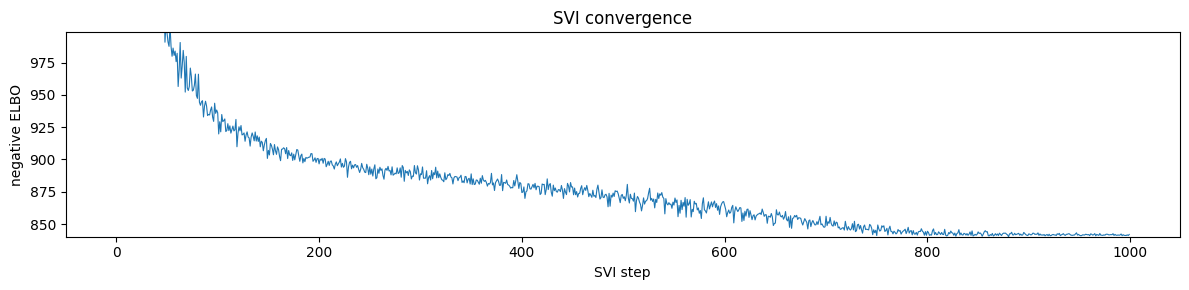

In [8]:
# Shapes: D_θ = 6 parameters; 1,000 guide draws

# today (numpyro)
# q(θ; ν), a full-covariance Gaussian over the unconstrained θ
guide = AutoMultivariateNormal(station_model, init_loc_fn=init_to_median)
# today (optax)
optimizer = optax.adam(0.02)
# today (numpyro)
# ℒ_ELBO(ν) = −ELBO, a Monte Carlo estimate from 2 particles
elbo = Trace_ELBO(num_particles=2)
# today (numpyro)
svi = SVI(station_model, guide, optimizer, elbo)
t0 = time.perf_counter()
# today (numpyro)
# ν⋆ = argmin_ν ℒ_ELBO(ν), 1000 Adam steps
svi_result = svi.run(jr.PRNGKey(3), 1000, times, y, mask, progress_bar=False)
jax.block_until_ready(svi_result.params)
svi_seconds = time.perf_counter() - t0
# today (numpyro)
# 1,000 draws θ ~ q(θ; ν⋆)
svi_samples = guide.sample_posterior(  # → {name: (1000,)}
    jr.PRNGKey(4), svi_result.params, sample_shape=(1000,)
)
final_loss = float(svi_result.losses[-100:].mean())  # → ()
print(f"SVI wall-clock: {svi_seconds:.1f} s for 1000 steps x 2 particles")
print(f"final negative ELBO (mean of last 100 steps): {final_loss:.1f}")

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(np.asarray(svi_result.losses), "C0", lw=0.8)
ax.set_ylim(np.percentile(np.asarray(svi_result.losses), [0, 95]))
ax.set_xlabel("SVI step")
ax.set_ylabel("negative ELBO")
ax.set_title("SVI convergence")
plt.tight_layout()
plt.show()

## 5. The two posteriors against the truth

For each parameter we print the posterior mean, standard deviation and 90 % interval from NUTS and from SVI, next to the value we simulated the data with.

In [9]:
param_names = list(truth)
header = (
    f"{'parameter':<12}{'truth':>8}  {'NUTS mean ± sd':>18}  "
    f"{'NUTS 90% interval':>22}  {'SVI mean ± sd':>18}  {'SVI 90% interval':>22}"
)
print(header)
for k in param_names:
    row = f"{k:<12}{truth[k]:>8.2f}"
    for s in (nuts_samples, svi_samples):
        v = np.asarray(s[k])
        lo, hi = np.percentile(v, [5, 95])
        inside = "in" if lo <= truth[k] <= hi else "out"
        row += (
            f"  {v.mean():>9.3f} ± {v.std():<6.3f}  "
            f"[{lo:>7.3f}, {hi:>7.3f}] {inside:>3}"
        )
    print(row)

parameter      truth      NUTS mean ± sd       NUTS 90% interval       SVI mean ± sd        SVI 90% interval
mean_temp      10.00     10.375 ± 0.204   [ 10.045,  10.709] out     10.359 ± 0.228   [  9.989,  10.740]  in
cos_amp        -8.00     -7.735 ± 0.316   [ -8.276,  -7.238]  in     -7.670 ± 0.309   [ -8.185,  -7.161]  in
sin_amp        -1.50     -1.217 ± 0.301   [ -1.701,  -0.730]  in     -1.218 ± 0.259   [ -1.641,  -0.786]  in
variance        4.00      3.521 ± 0.460   [  2.874,   4.389]  in      3.588 ± 0.463   [  2.907,   4.385]  in
lengthscale     4.00      3.767 ± 0.314   [  3.320,   4.319]  in      3.885 ± 0.280   [  3.441,   4.348]  in
noise_var       0.25      0.194 ± 0.025   [  0.156,   0.238] out      0.196 ± 0.028   [  0.154,   0.243] out


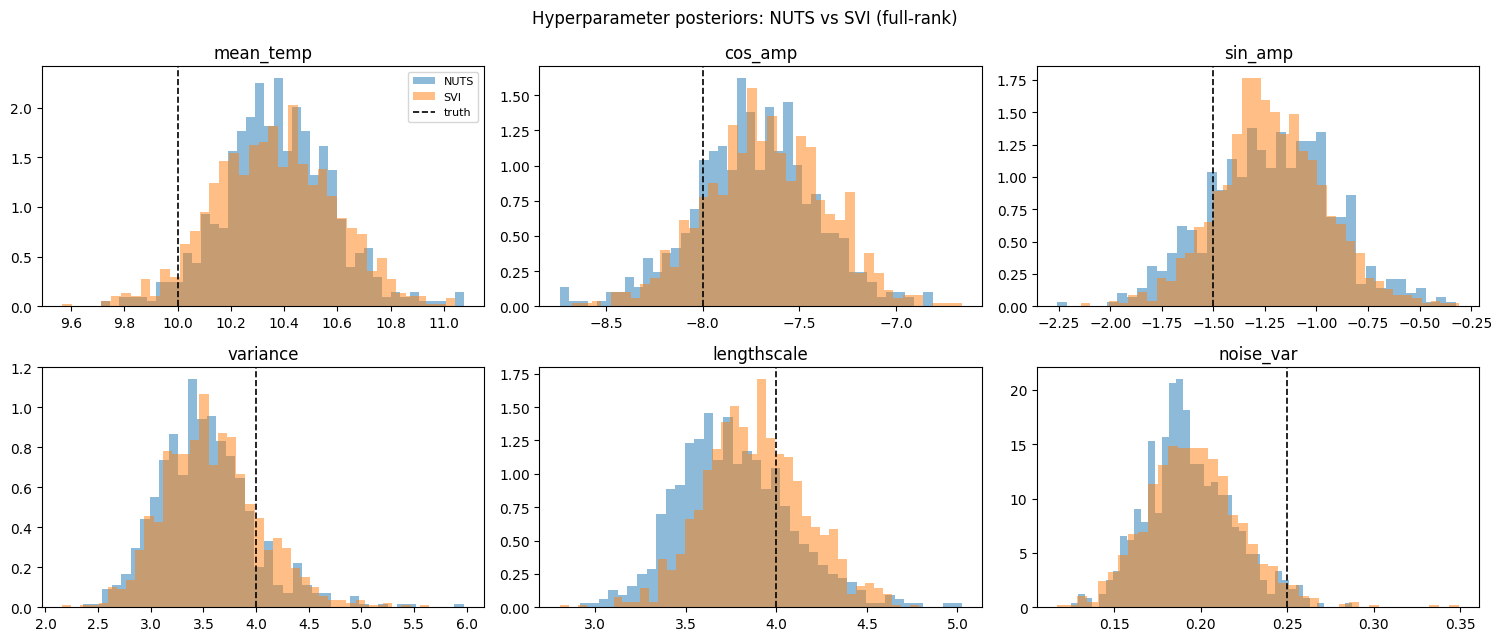

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, k in zip(axes.ravel(), param_names, strict=True):
    for s, label, color in ((nuts_samples, "NUTS", "C0"), (svi_samples, "SVI", "C1")):
        ax.hist(
            np.asarray(s[k]), bins=40, density=True, alpha=0.5, color=color, label=label
        )
    ax.axvline(truth[k], color="k", ls="--", lw=1.2, label="truth")
    ax.set_title(k)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Hyperparameter posteriors: NUTS vs SVI (full-rank)")
plt.tight_layout()
plt.show()

The NUTS and SVI marginals overlap for every parameter, and their posterior means differ by at most 0.12 (the lengthscale, 3.77 against 3.89 days). With the path integrated out, the six-parameter posterior is close enough to Gaussian in the unconstrained space for a full-rank guide to match it. The NUTS 90 % intervals contain four of the six true values and the SVI ones contain five. Both methods put the noise variance $\sigma_\varepsilon^2$ low (posterior mean 0.19 against 0.25), and the NUTS interval for the mean temperature stops at 10.05 °C, just above the true 10 °C; both misses are about two posterior standard deviations. Since the two methods agree, these misses belong to this one realisation of the record and not to either fitting method.

## 6. Prediction through the gaps

For one parameter draw, `MarkovGPPrior.condition(y, noise_var, mask=mask)` runs the filter and RTS smoother and returns a `ConditionedMarkovGP`. Its `predict(t_star)` gives the posterior mean and variance of the latent $\mu(t_*) + f(t_*)$ at any test times $t_*$. It re-runs the smoother over the merged grid with the test times masked out of the update. The conditioned GP keeps the mask, so the missing days stay unobserved. We do this for $N_{\mathcal{E}} = 200$ NUTS draws $\boldsymbol{\theta}^{(e)}$, $e \in \mathcal{E}$, at once with `jax.vmap` and average them, so the bands carry the hyperparameter uncertainty as well as the uncertainty of the path. With $\mu_*^{(e)} \in \mathbb{R}$ and $(\sigma_*^{(e)})^2 \in \mathbb{R}_{>0}$ the posterior mean and variance under draw $e$,

$$\mathbb{E}[\mu(t_*) + f(t_*) \mid \mathbf{y}] \approx \bar{\mu}_* = \frac{1}{N_{\mathcal{E}}} \sum_{e \in \mathcal{E}} \mu_*^{(e)}$$

$$\mathbb{V}[\mu(t_*) + f(t_*) \mid \mathbf{y}] \approx \frac{1}{N_{\mathcal{E}}} \sum_{e \in \mathcal{E}} (\sigma_*^{(e)})^2 + \frac{1}{N_{\mathcal{E}}} \sum_{e \in \mathcal{E}} (\mu_*^{(e)} - \bar{\mu}_*)^2$$

and a new observation $y_*$ adds $(\sigma_\varepsilon^{(e)})^2$ to each $(\sigma_*^{(e)})^2$. The dense grid has a test time every six hours over the record and for 30 days beyond its end.

In [11]:
# Shapes: N = 730 days; M = 3,040 test times (every 6 h); N_E = 200 draws

t_dense = jnp.arange(0.0, N + 30.0, 0.25)  # → (M,)


def predict_one(theta, t_star):
    # today (pyrox_ssm)
    sde = MaternSDE(theta["variance"], theta["lengthscale"], order=1)
    # today (pyrox_ssm)
    prior = MarkovGPPrior(
        sde,
        times,
        mean_fn=lambda t: climatology(
            t, theta["mean_temp"], theta["cos_amp"], theta["sin_amp"]
        ),
    )
    # today (pyrox_ssm)
    # p(x_1:N ∣ y; θ⁽ᵉ⁾) by the Kalman filter and RTS smoother
    cond = prior.condition(y, theta["noise_var"], mask=mask)
    # today (pyrox_ssm)
    # μ_*⁽ᵉ⁾, (σ_*⁽ᵉ⁾)² of μ(t_*) + f(t_*)
    mean, var = cond.predict(t_star)  # (M,) → (M,), (M,)
    # (σ_*⁽ᵉ⁾)² + (σ_ε⁽ᵉ⁾)² for a new observation y_*
    obs_var = var + theta["noise_var"]  # → (M,)
    return mean, var, obs_var


def posterior_predict(samples, t_star, n_draws=200):
    num_samples = samples["variance"].shape[0]
    # N_E draws θ⁽ᵉ⁾, evenly spaced through the chain
    idx = jnp.linspace(0, num_samples - 1, n_draws).astype(int)  # → (N_E,)
    draws = {k: v[idx] for k, v in samples.items()}
    # today (jax)
    predict_draws = jax.vmap(predict_one, in_axes=(0, None))
    # today (jax)
    predict_draws = jax.jit(predict_draws)
    # μ_*⁽ᵉ⁾, (σ_*⁽ᵉ⁾)², (σ_*⁽ᵉ⁾)² + (σ_ε⁽ᵉ⁾)²
    means, f_vars, y_vars = predict_draws(draws, t_star)  # → 3 × (N_E, M)
    # μ̄_* = (1/N_E) ∑ₑ μ_*⁽ᵉ⁾
    mean = einx.mean("member test -> test", means)  # (N_E, M) → (M,)
    # (1/N_E) ∑ₑ (μ_*⁽ᵉ⁾ − μ̄_*)²
    spread = einx.var("member test -> test", means)  # (N_E, M) → (M,)
    # (1/N_E) ∑ₑ (σ_*⁽ᵉ⁾)²
    f_var_mean = einx.mean("member test -> test", f_vars)  # (N_E, M) → (M,)
    # 𝕍[μ(t_*) + f(t_*) ∣ y] ≈ (1/N_E) ∑ₑ (σ_*⁽ᵉ⁾)² + spread
    f_var = f_var_mean + spread  # → (M,)
    # (1/N_E) ∑ₑ ((σ_*⁽ᵉ⁾)² + (σ_ε⁽ᵉ⁾)²)
    y_var_mean = einx.mean("member test -> test", y_vars)  # (N_E, M) → (M,)
    # the same for a new observation y_*
    y_var = y_var_mean + spread  # → (M,)
    return mean, f_var, y_var


t0 = time.perf_counter()
f_mean, f_var, y_var = posterior_predict(nuts_samples, t_dense)  # → 3 × (M,)
jax.block_until_ready(f_mean)
pred_seconds = time.perf_counter() - t0
f_mean_svi, f_var_svi, _ = posterior_predict(svi_samples, t_dense)  # → 2 × (M,)
print(
    f"prediction at {t_dense.shape[0]} times for 200 draws: "
    f"{pred_seconds:.1f} s (with JIT)"
)

prediction at 3040 times for 200 draws: 4.6 s (with JIT)


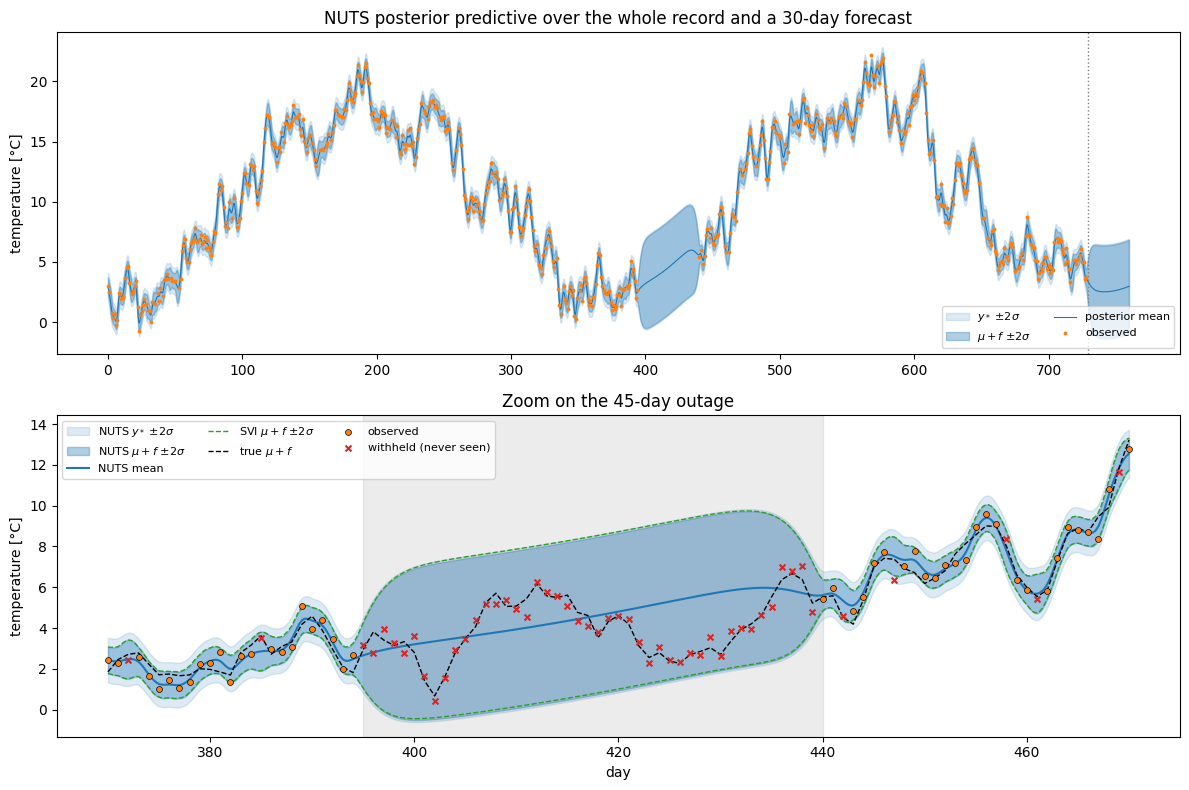

In [12]:
f_sd, y_sd, f_sd_svi = np.sqrt(f_var), np.sqrt(y_var), np.sqrt(f_var_svi)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
ax = axes[0]
ax.fill_between(
    t_dense,
    f_mean - 2 * y_sd,
    f_mean + 2 * y_sd,
    color="C0",
    alpha=0.15,
    label=r"$y_*$ $\pm 2\sigma$",
)
ax.fill_between(
    t_dense,
    f_mean - 2 * f_sd,
    f_mean + 2 * f_sd,
    color="C0",
    alpha=0.35,
    label=r"$\mu + f$ $\pm 2\sigma$",
)
ax.plot(t_dense, f_mean, "C0", lw=0.8, label="posterior mean")
ax.scatter(times[mask], y[mask], c="C1", s=3, zorder=5, label="observed")
ax.axvline(N - 1, color="grey", ls=":", lw=1)
ax.set_ylabel("temperature [°C]")
ax.set_title("NUTS posterior predictive over the whole record and a 30-day forecast")
ax.legend(loc="lower right", fontsize=8, ncol=2)

ax = axes[1]
win = (t_dense >= 370) & (t_dense <= 470)
twin = (times >= 370) & (times <= 470)
ax.fill_between(
    t_dense[win],
    (f_mean - 2 * y_sd)[win],
    (f_mean + 2 * y_sd)[win],
    color="C0",
    alpha=0.15,
    label=r"NUTS $y_*$ $\pm 2\sigma$",
)
ax.fill_between(
    t_dense[win],
    (f_mean - 2 * f_sd)[win],
    (f_mean + 2 * f_sd)[win],
    color="C0",
    alpha=0.35,
    label=r"NUTS $\mu + f$ $\pm 2\sigma$",
)
ax.plot(t_dense[win], f_mean[win], "C0", lw=1.5, label="NUTS mean")
ax.plot(
    t_dense[win],
    (f_mean_svi - 2 * f_sd_svi)[win],
    "C2--",
    lw=1,
    label=r"SVI $\mu + f$ $\pm 2\sigma$",
)
ax.plot(t_dense[win], (f_mean_svi + 2 * f_sd_svi)[win], "C2--", lw=1)
ax.plot(times[twin], (mu_true + f_true)[twin], "k--", lw=1, label=r"true $\mu + f$")
ax.scatter(
    times[twin & mask],
    y[twin & mask],
    c="C1",
    edgecolors="k",
    linewidths=0.5,
    s=18,
    zorder=5,
    label="observed",
)
ax.scatter(
    times[twin & ~mask],
    y_full[twin & ~mask],
    marker="x",
    c="C3",
    s=18,
    zorder=5,
    label="withheld (never seen)",
)
ax.axvspan(395, 440, color="grey", alpha=0.15)
ax.set_xlabel("day")
ax.set_ylabel("temperature [°C]")
ax.set_title("Zoom on the 45-day outage")
ax.legend(loc="upper left", fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

Inside the outage, the band widens to the climatology plus the stationary anomaly spread within a few lengthscales of its edges. The posterior mean relaxes to the seasonal cycle, and the same happens in the forecast after the last day. Short random gaps barely widen the band, because the neighbouring days pin the anomaly down. The SVI band lies on top of the NUTS one.

Because the data are simulated, we know the values the model never saw, so we can check the predictive bands. Below we compute the fraction of withheld days whose value falls inside the $\pm 2\sigma$ band for $y_*$ (two predictive standard deviations), which should be close to 95 %.

In [13]:
# Shapes: N_miss = 134 withheld days; N_E = 200 draws

t_withheld = times[~mask]  # → (N_miss,)
y_mean_w, _, y_var_w = posterior_predict(nuts_samples, t_withheld)  # → 2 × (N_miss,)
# r = y − μ̄_* on the withheld days
residual = y_full[~mask] - y_mean_w  # → (N_miss,)
# z = r / σ_*, with σ_* the predictive standard deviation of y_*
z = residual / jnp.sqrt(y_var_w)  # → (N_miss,)
for label, sel in (
    ("outage", outage[~mask]),
    ("random dropouts", ~outage[~mask]),
    ("all withheld", jnp.ones_like(z, dtype=bool)),
):
    # fraction of days with |z| < 2
    cover = float(jnp.mean(jnp.abs(z[sel]) < 2.0))  # → ()
    # RMSE = √(mean of r²)
    rmse = float(jnp.sqrt(jnp.mean(residual[sel] ** 2)))  # → ()
    print(
        f"{label:<16} n = {int(sel.sum()):>3}  "
        f"coverage of ±2σ = {100 * cover:5.1f} %  RMSE = {rmse:.2f} °C"
    )

outage           n =  45  coverage of ±2σ = 100.0 %  RMSE = 1.61 °C


random dropouts  n =  89  coverage of ±2σ =  95.5 %  RMSE = 0.69 °C


all withheld     n = 134  coverage of ±2σ =  97.0 %  RMSE = 1.09 °C


All 45 outage days and 95.5 % of the 89 isolated missing days fall inside the $\pm 2\sigma$ band for a new observation. The error is much larger inside the outage (RMSE 1.61 °C) than at isolated missing days (0.69 °C), as it should be. An isolated day is pinned down by its neighbours, whereas in the middle of the outage the best the model can do is the climatology, and its band says so.

## 7. Cost

Each NUTS leapfrog step and each SVI particle costs one Kalman filter pass over the $N$ days plus its reverse-mode gradient, which is $\mathcal{O}(N D_x^3)$ with $D_x = 2$ for Matérn-3/2. In the cell below we time one jitted log density and gradient at this record's length and at records of the same daily station that are 4 and 16 times longer. So we measure the linear scaling rather than assert it. For the crossover against the dense $\mathcal{O}(N^3)$ Cholesky path, see section 4 of [Kalman filtering and RTS smoothing](markov_gp_kalman.ipynb).

In [14]:
def time_grad(n, repeats=10):
    # Shapes: n days (N, 4N or 16N); D_θ = 3 log parameters (σ_f², ℓ, σ_ε²)
    t = jnp.arange(n, dtype=jnp.float64)  # → (n,)
    noise = jr.normal(jr.PRNGKey(0), (n,))  # → (n,)
    obs = jnp.sin(OMEGA * t) + noise  # → (n,)
    all_observed = jnp.ones(n, dtype=bool)  # → (n,) bool

    def neg_log_marginal(log_params):
        params = jnp.exp(log_params)  # → (3,)
        # today (pyrox_ssm)
        sde = MaternSDE(params[0], params[1], order=1)
        # today (pyrox_ssm)
        prior = MarkovGPPrior(sde, t)
        # today (pyrox_ssm)
        # ℒ_NLL(θ) = −log p(y; θ), one Kalman filter pass
        log_marginal = prior.log_marginal(obs, params[2], mask=all_observed)
        return -log_marginal

    # today (jax)
    # ℒ_NLL(θ) and ∇_θ ℒ_NLL, jitted once
    loss_and_grad = jax.jit(jax.value_and_grad(neg_log_marginal))
    log_params = jnp.log(jnp.array([4.0, 4.0, 0.25]))  # → (3,)
    jax.block_until_ready(loss_and_grad(log_params))
    t0 = time.perf_counter()
    for _ in range(repeats):
        jax.block_until_ready(loss_and_grad(log_params))
    return (time.perf_counter() - t0) / repeats


grad_ms = {n: 1e3 * time_grad(n) for n in (N, 4 * N, 16 * N)}
for n, ms in grad_ms.items():
    print(
        f"N = {n:>6}: {ms:7.3f} ms per log density + gradient  "
        f"({1e6 * ms / 1e3 / n:.2f} µs per day)"
    )
print()
print(
    f"NUTS: {nuts_seconds:6.1f} s  "
    f"(2 chains x 500 iterations, {n_grad} leapfrog steps after warm-up)"
)
print(f"SVI : {svi_seconds:6.1f} s  (1000 steps x 2 particles)")
print(f"prediction: {pred_seconds:.1f} s  (200 draws x {t_dense.shape[0]} times)")

N =    730:  21.243 ms per log density + gradient  (29.10 µs per day)
N =   2920:  77.505 ms per log density + gradient  (26.54 µs per day)
N =  11680: 285.415 ms per log density + gradient  (24.44 µs per day)

NUTS:   91.9 s  (2 chains x 500 iterations, 3696 leapfrog steps after warm-up)
SVI :   28.3 s  (1000 steps x 2 particles)
prediction: 4.6 s  (200 draws x 3040 times)


The time per day stays flat while the record grows sixteen-fold, so one log density and its gradient scale linearly in $N$. A dense GP would pay an $\mathcal{O}(N^3)$ Cholesky on every one of them. NUTS is the expensive step because it evaluates the gradient thousands of times (the leapfrog count above, plus warm-up). SVI needs about a thousand evaluations per particle, and the posterior predictive is a few filter-and-smoother passes per draw, vectorised over the draws.

## Summary

- A Markov-GP regression for one station is a plain NumPyro function: priors on the SDE kernel, the mean function and the noise, then `markov_gp_factor(..., mask=mask)`. Missing days are a mask, not a reindexing, and `NaN` placeholders are safe.
- The trace holds only the six parameters, as the Kalman filter integrates the latent path out. So NUTS and SVI both run on a six-dimensional posterior. Here they agree with each other, and their 90 % intervals contain four (NUTS) and five (SVI) of the six true values.
- `MarkovGPPrior.condition(..., mask=mask).predict(t_star)` gives the smoothed posterior at any times, inside gaps and beyond the record. Averaging it over posterior draws gives bands that include the hyperparameter uncertainty.
- Every step is linear in the record length.

The next examples change one piece of this model at a time: many sites with pooled hyperparameters, a regional signal shared between sites, and non-Gaussian observations. For the kernels in state-space form see [Matérn kernels in state-space form](markov_gp_sde_kernels.ipynb).